# Best fitted trigonometric function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

We want to adjust the next function

$$y = B + C \cos(x) + D \sin(x) + E \cos(2x) + F \sin(2x) + G \cos(3x) + H \sin(3x)$$

In [2]:
points = np.array([[-4,-1],[-3,0],[-2,-1.5],[-1,0.5],[0,1],[1,-1],[2,-0.5,],[3,2],[4,-1]])

points_x = points[:,0]
points_y = points[:,1]
cos_x  = np.cos(points_x)
sin_x  = np.sin(points_x)
cos_2x = np.cos(2*points_x)
sin_2x = np.sin(2*points_x)
cos_3x = np.cos(3*points_x)
sin_3x = np.sin(3*points_x)

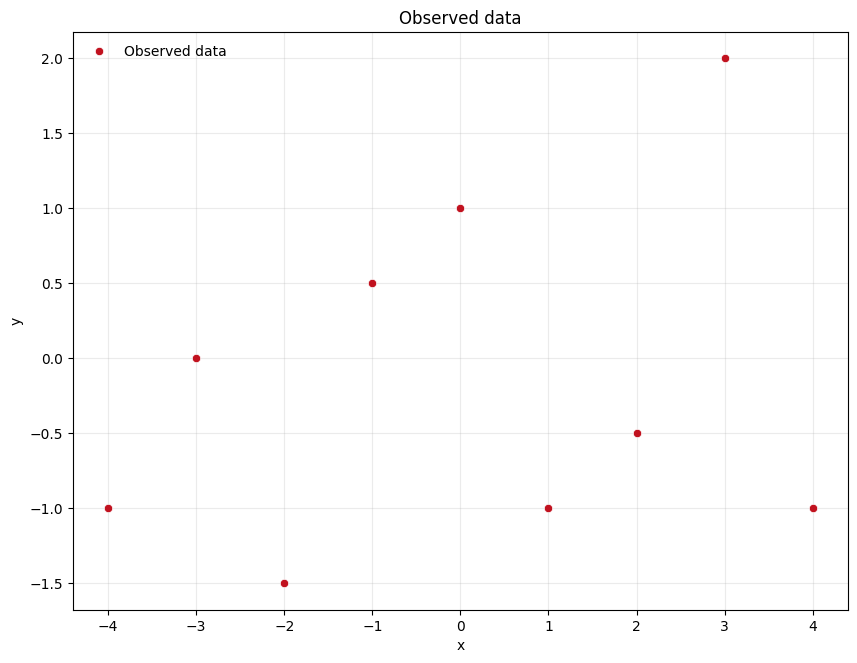

In [3]:
plt.figure(figsize=(10,7.5))
plt.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Observed data')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Compute coefficients and calculate SSE

In [4]:
n = len(points)
Y = points_y
X = np.vstack([np.ones(n), cos_x, sin_x, cos_2x, sin_2x, cos_3x, sin_3x]).T
p = X.shape[1]

In [5]:
# We compute the coeff.
B, C, D, E, F, G, H = np.linalg.lstsq(X, Y, rcond=None)[0]
params  = [B, C, D, E, F, G, H]

# Calculate the SSE
SSE = np.linalg.lstsq(X, Y, rcond=None)[1][0]

Computing confidence and prediction intervals

In [6]:
alpha = 0.05
x_grid = np.linspace(-4.5, 4.5, 100)
X_grid = np.vstack([np.ones(len(x_grid)), np.cos(x_grid), np.sin(x_grid), np.cos(2*x_grid), np.sin(2*x_grid), np.cos(3*x_grid), np.sin(3*x_grid)]).T

In [7]:
# Computing confidence interval
aux_t_conf = np.sqrt(SSE/(n-p)*(np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
Y_grid_hat = X_grid @ params
ci_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_conf
ci_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_conf

# Computing prediction interval
aux_t_pred = np.sqrt(SSE/(n-p)*(1+np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
Y_grid_hat = X_grid @ params
pi_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_pred
pi_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_pred

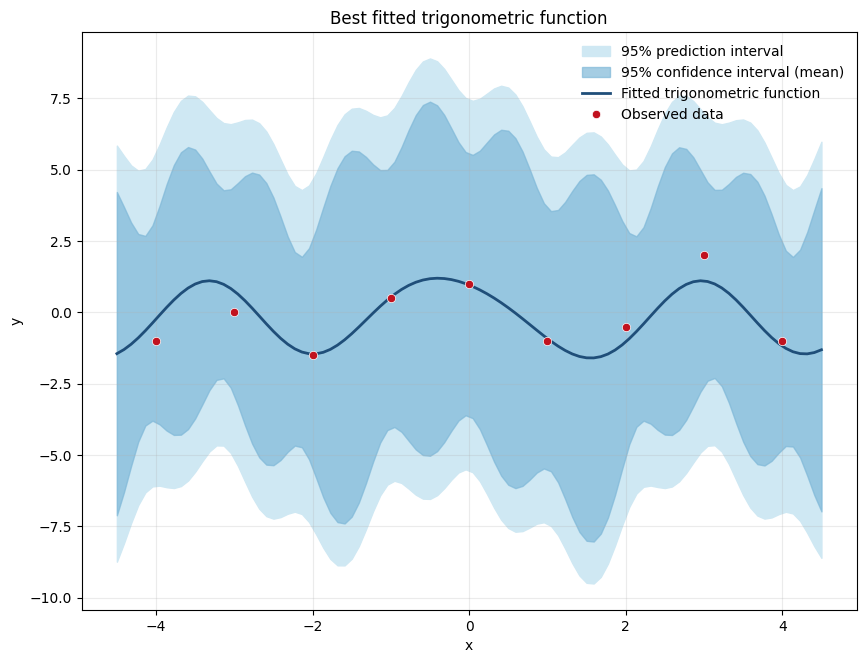

In [8]:
plt.figure(figsize=(10,7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(x_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(x_grid, ci_lower, ci_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(x_grid, B+C*np.cos(x_grid)+D*np.sin(x_grid)+E*np.cos(2*x_grid)+F*np.sin(2*x_grid)+G*np.cos(3*x_grid)+H*np.sin(3*x_grid),
         color='#1f4e79', lw=2, label='Fitted trigonometric function')

# Observed data on top, dark and distinct
plt.plot(points_x, points_y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Best fitted trigonometric function')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)